# INF201 – Deliverable 1: Værdata fra Ås
**maand1153 (Max Carl Andresen) og samir9125 (Sam Mirtaheri)**

Vi undersøker temperatur og nedbør ved Ås (SN17850) i 2025 og sammenligner
med 1925. Data hentes fra Meteorologisk institutts Frost-API.



## Task 1 – Daglig gjennomsnittstemperatur
Vi bruker kalenderdøgnets gjennomsnitt (`PT0H`). Sluttdatoen i forespørselen
er 1. januar 2026, slik at hele 2025 er med. Manglende datoer beholdes
som tomme verdier, og vi skriver ut antall tilgjengelige dager.


Antall dager med temperaturdata: 365


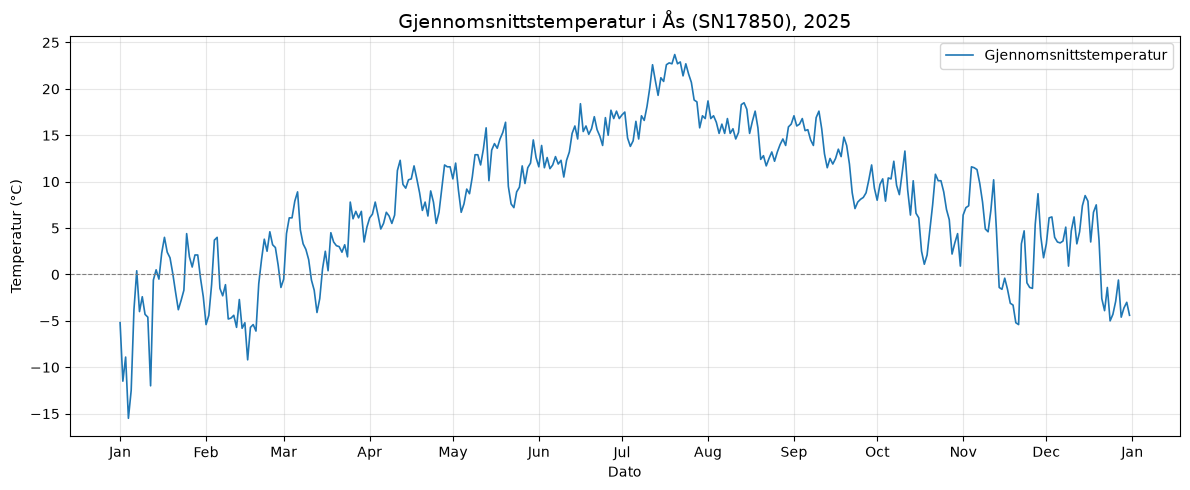

Lufttemperatur i Ås, 2025
  Statistikk  Temperatur (°C)
Gjennomsnitt             7.87
      Median             8.30
     Minimum           -15.50
    Maksimum            23.70


In [1]:
# maand1153 (Max Carl Andresen) og samir9125 (Sam Mirtaheri)

from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd
import requests
import yaml


# Les klient-ID fra fil
ID_FILE = Path("frost_client_id.txt")
if not ID_FILE.is_file():
    raise FileNotFoundError(
        f"Fant ikke {ID_FILE.resolve()}. "
        "Legg filen i notebookens arbeidsmappe."
    )

client_id = ID_FILE.read_text(encoding="utf-8").strip()
if not client_id:
    raise ValueError(f"{ID_FILE} er tom. Legg Frost-klient-ID-en i filen.")

# Hent gjennomsnittstemperatur fra Frost
endpoint = "https://frost.met.no/observations/v0.jsonld"
parameters = {
    "sources": "SN17850",
    "elements": "mean(air_temperature P1D)",
    "referencetime": "2025-01-01/2026-01-01",  # sluttdato er ikke inkludert
}

response = requests.get(
    endpoint,
    params=parameters,
    auth=(client_id, ""),
    timeout=30,
)
response.raise_for_status()
data = response.json()["data"]

# Gjør JSON-dataene om til en DataFrame
rows = []
for item in data:
    for obs in item["observations"]:
        rows.append(
            {
                "time": item["referenceTime"],
                "temperature": obs["value"],
                "time_offset": obs.get("timeOffset"),
            }
        )

if not rows:
    raise ValueError("Frost returnerte ingen temperaturdata for tidsrommet.")

df = pd.DataFrame(rows)
df["time"] = pd.to_datetime(df["time"])
df["temperature"] = pd.to_numeric(df["temperature"], errors="raise")

# Velg observasjonene som representerer gjennomsnittstemperaturen for datoen
if "PT0H" in df["time_offset"].values:
    df = df[df["time_offset"] == "PT0H"]

df = df.drop_duplicates(subset="time").set_index("time").sort_index()
temps = df["temperature"].reindex(
    pd.date_range("2025-01-01", "2025-12-31", tz="UTC")
)
print(f"Antall dager med temperaturdata: {temps.count()}")

# Plot gjennomsnittstemperaturen
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(
    temps.index,
    temps.values,
    color="tab:blue",
    linewidth=1.2,
    label="Gjennomsnittstemperatur",
)
ax.axhline(0, color="grey", linewidth=0.8, linestyle="--")
ax.set_title("Gjennomsnittstemperatur i Ås (SN17850), 2025", fontsize=14)
ax.set_xlabel("Dato")
ax.set_ylabel("Temperatur (°C)")
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

# Oppsummer gjennomsnittstemperaturen
summary = pd.DataFrame(
    {
        "Statistikk": ["Gjennomsnitt", "Median", "Minimum", "Maksimum"],
        "Temperatur (°C)": [
            temps.mean(),
            temps.median(),
            temps.min(),
            temps.max(),
        ],
    }
)

print("Lufttemperatur i Ås, 2025")
print(summary.to_string(index=False, float_format="%.2f"))


## Felles funksjon for de neste forespørslene
Vi gjenbruker fremgangsmåten fra oppgave 1 og velger en døgnserie per
måling. Temperatur bruker `PT0H`. Nedbør og maksimumstemperatur bruker
`PT18H`, som har en komplett døgnserie for Ås i 2025. Disse meteorologiske
døgnene har en annen døgnavgrensning enn kalenderdøgnets middeltemperatur.
Figurene viser datoene slik Frost oppgir dem.


In [2]:
def get_daily_data(station_id, year, element, time_offset):
    """Hent én døgnserie fra Frost og behold alle datoene i året."""
    parameters = {
        "sources": station_id,
        "elements": element,
        "referencetime": f"{year}-01-01/{year + 1}-01-01",
        "timeoffsets": time_offset,
    }
    response = requests.get(
        endpoint, params=parameters, auth=(client_id, ""), timeout=30
    )
    response.raise_for_status()

    # Gjør JSON-dataene om til en DataFrame
    rows = []
    for item in response.json()["data"]:
        for obs in item["observations"]:
            if obs["timeOffset"] == time_offset:
                rows.append({
                    "time": item["referenceTime"],
                    "value": obs["value"],
                })

    daily = pd.DataFrame(rows)
    daily["time"] = pd.to_datetime(daily["time"], utc=True).dt.normalize()
    daily = daily.set_index("time").sort_index()
    if daily.index.has_duplicates:
        raise ValueError("Forespørselen ga flere målinger for samme dato.")

    dates = pd.date_range(
        f"{year}-01-01", f"{year}-12-31", tz="UTC"
    )
    return daily["value"].reindex(dates)


## Task 2 – Temperatur og nedbør
Temperatur vises som en linje og døgnnedbør som søyler. Separate y-akser
gjør at begge enhetene kan leses °C til venstre og mm til høyre.
Kurvenes høyder kan derfor ikke sammenlignes direkte.


Antall dager med nedbørdata: 365


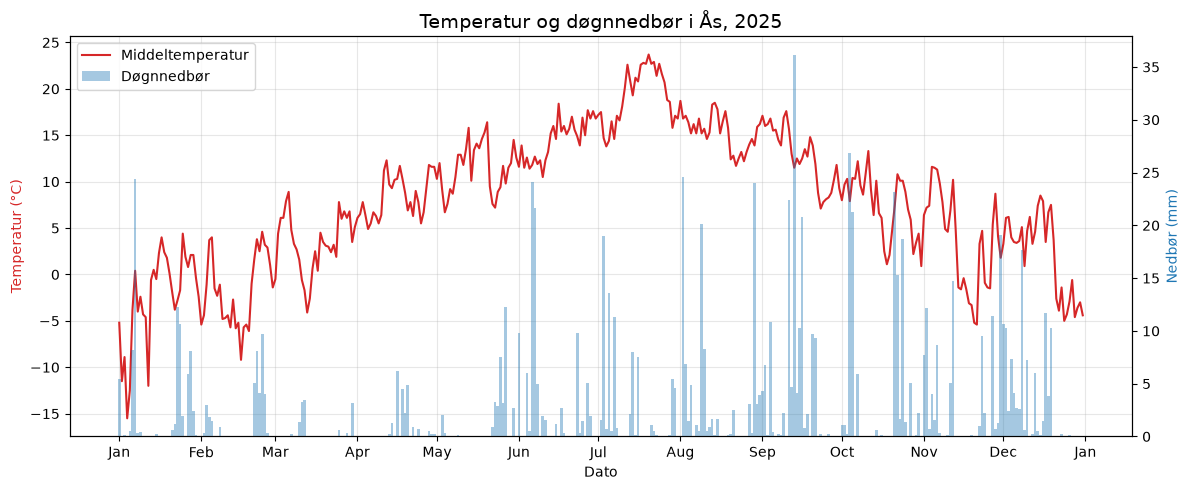

In [3]:
# Hent nedbør over 24 timer
precipitation = get_daily_data(
    "SN17850", 2025, "sum(precipitation_amount P1D)", "PT18H"
)
print(f"Antall dager med nedbørdata: {precipitation.count()}")

# Plot temperatur og nedbør med hver sin y-akse
fig, ax = plt.subplots(figsize=(12, 5))
ax_rain = ax.twinx()
ax_rain.bar(
    precipitation.index, precipitation, width=1,
    color="tab:blue", alpha=0.4, label="Døgnnedbør",
)
ax.plot(temps.index, temps, color="tab:red", label="Middeltemperatur")
ax.set_title("Temperatur og døgnnedbør i Ås, 2025", fontsize=14)
ax.set_xlabel("Dato")
ax.set_ylabel("Temperatur (°C)", color="tab:red")
ax_rain.set_ylabel("Nedbør (mm)", color="tab:blue")
ax_rain.set_ylim(bottom=0)
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.grid(alpha=0.3)
lines, labels = ax.get_legend_handles_labels()
bars, rain_labels = ax_rain.get_legend_handles_labels()
ax.legend(lines + bars, labels + rain_labels, loc="upper left")
fig.tight_layout()
plt.show()


## Task 3 – Sammenligning med 1925
Vi henter samme temperaturmål for 1925. Datoene fra 1925 flyttes til
2025 i figuren for å sammenligne samme tid på året. Tabellens verdier
beregnes fra de opprinnelige observasjonene. To enkeltår er ikke nok til
å trekke en konklusjon om langsiktige klimaendringer.


Antall dager med temperaturdata i 1925: 365


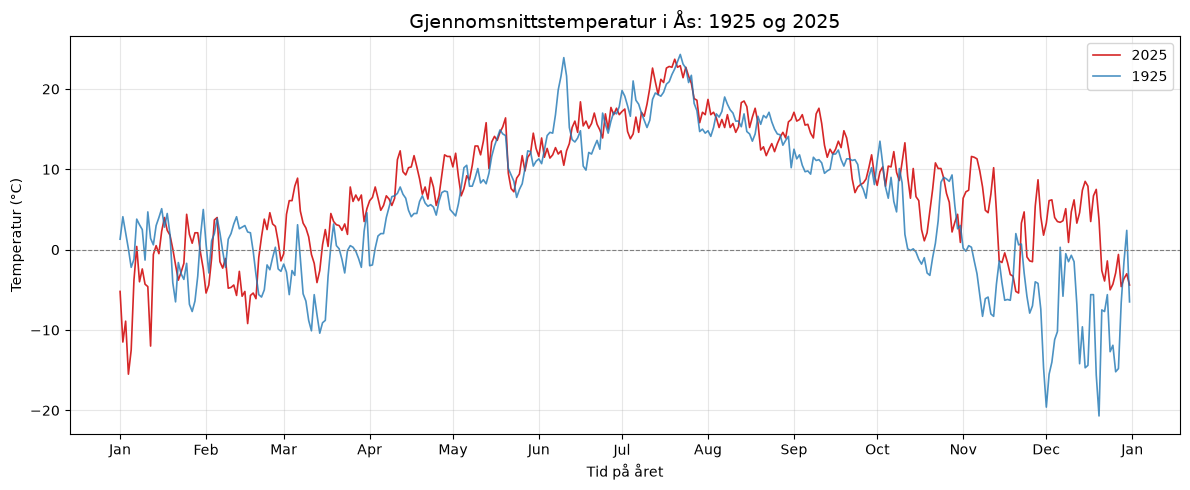

Lufttemperatur i Ås, 1925 og 2025
  Statistikk  1925 (°C)  2025 (°C)
Gjennomsnitt       5.28       7.87
      Median       5.30       8.30
     Minimum     -20.70     -15.50
    Maksimum      24.30      23.70


In [4]:
# Hent gjennomsnittstemperaturen fra 100 år tidligere
old_temps = get_daily_data(
    "SN17850", 1925, "mean(air_temperature P1D)", "PT0H"
)
print(f"Antall dager med temperaturdata i 1925: {old_temps.count()}")

# Legg begge årene på samme datoakse
comparison_dates = old_temps.index.map(lambda date: date.replace(year=2025))
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(temps.index, temps, color="tab:red", linewidth=1.2, label="2025")
ax.plot(
    comparison_dates, old_temps, color="tab:blue",
    linewidth=1.2, alpha=0.8, label="1925",
)
ax.axhline(0, color="grey", linewidth=0.8, linestyle="--")
ax.set_title("Gjennomsnittstemperatur i Ås: 1925 og 2025", fontsize=14)
ax.set_xlabel("Tid på året")
ax.set_ylabel("Temperatur (°C)")
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

# Oppsummer temperaturene for begge årene
historical_summary = pd.DataFrame({
    "Statistikk": ["Gjennomsnitt", "Median", "Minimum", "Maksimum"],
    "1925 (°C)": [
        old_temps.mean(), old_temps.median(), old_temps.min(), old_temps.max()
    ],
    "2025 (°C)": [temps.mean(), temps.median(), temps.min(), temps.max()],
})
print("Lufttemperatur i Ås, 1925 og 2025")
print(historical_summary.to_string(index=False, float_format="%.2f"))


## Task 4 – Hetebølger
En hetebølge er minst fem sammenhengende dager med maksimumstemperatur
på minst 27 °C. Én sammenhengende periode telles én gang, selv om den
varer mer enn fem dager. En manglende observasjon bryter perioden.

Funksjonen tar stasjonsnavn eller ID og år. Et navn må identifisere én
stasjon entydig. Resultatet lagres i YAML med de samme feltene som i
`heatwave_summary_example.yml`: `dates`, `station_id`, `station_name`
og `year`. Antallet returneres av funksjonen. En tom liste betyr at
vi ikke finner noen hetebølger i de tilgjengelige observasjonene.


In [5]:
def count_heatwaves(station, year, output_file=None):
    """Tell hetebølger for en stasjon og skriv periodene til en YAML-fil."""
    # Finn stasjonens navn og ID
    station = station.strip()
    source_parameters = {"ids": station} if station.upper().startswith(
        "SN"
    ) and station[2:].isdigit() else {"name": station}
    response = requests.get(
        "https://frost.met.no/sources/v0.jsonld",
        params=source_parameters, auth=(client_id, ""), timeout=30,
    )
    response.raise_for_status()
    sources = response.json()["data"]
    if "name" in source_parameters:
        sources = [
            source for source in sources
            if source["name"].casefold() == station.casefold()
        ]
    if len(sources) != 1:
        raise ValueError("Oppgi et entydig stasjonsnavn eller en stasjons-ID.")
    station_id = sources[0]["id"]
    station_name = sources[0]["name"]

    # Hent maksimumstemperaturen for hvert døgn
    max_temps = get_daily_data(
        station_id, year, "max(air_temperature P1D)", "PT18H"
    )
    print(f"Dager med maksimumstemperatur i {year}: {max_temps.count()}")

    # Finn sammenhengende perioder med minst fem varme dager
    periods = []
    start = None
    duration = 0
    for date, temperature in max_temps.items():
        if pd.notna(temperature) and temperature >= 27:
            if start is None:
                start = date
            duration += 1
        else:
            if duration >= 5:
                end = date - pd.Timedelta(days=1)
                periods.append(f"{start:%Y-%m-%d} - {end:%Y-%m-%d}")
            start = None
            duration = 0
    if duration >= 5:
        end = max_temps.index[-1]
        periods.append(f"{start:%Y-%m-%d} - {end:%Y-%m-%d}")

    # Skriv oppsummeringen i samme format som eksempelfilen
    summary = {
        "dates": periods,
        "station_id": station_id,
        "station_name": station_name,
        "year": year,
    }
    if output_file is None:
        output_file = f"heatwave_summary_{station_id}_{year}.yml"
    with Path(output_file).open("w", encoding="utf-8") as file:
        yaml.safe_dump(summary, file, allow_unicode=True, sort_keys=False)
    return len(periods)


# Tell hetebølgene i Ås i 2025
number_of_heatwaves = count_heatwaves("SN17850", 2025)
print(f"Antall hetebølger i Ås i 2025: {number_of_heatwaves}")
print(Path("heatwave_summary_SN17850_2025.yml").read_text(encoding="utf-8"))


Dager med maksimumstemperatur i 2025: 365
Antall hetebølger i Ås i 2025: 1
dates:
- 2025-07-16 - 2025-07-22
station_id: SN17850
station_name: ÅS
year: 2025



## Task 5 – Sju dagers glidende gjennomsnitt
For hver dato beregner vi gjennomsnittet av denne dagen og de seks
foregående kalenderdagene. Vi krever sju gyldige observasjoner, så de
første seks dagene får ingen verdi. Manglende dager fylles ikke med
konstruerte temperaturer. Utjevningen gjør det lettere å se utviklingen
bak de daglige svingningene.


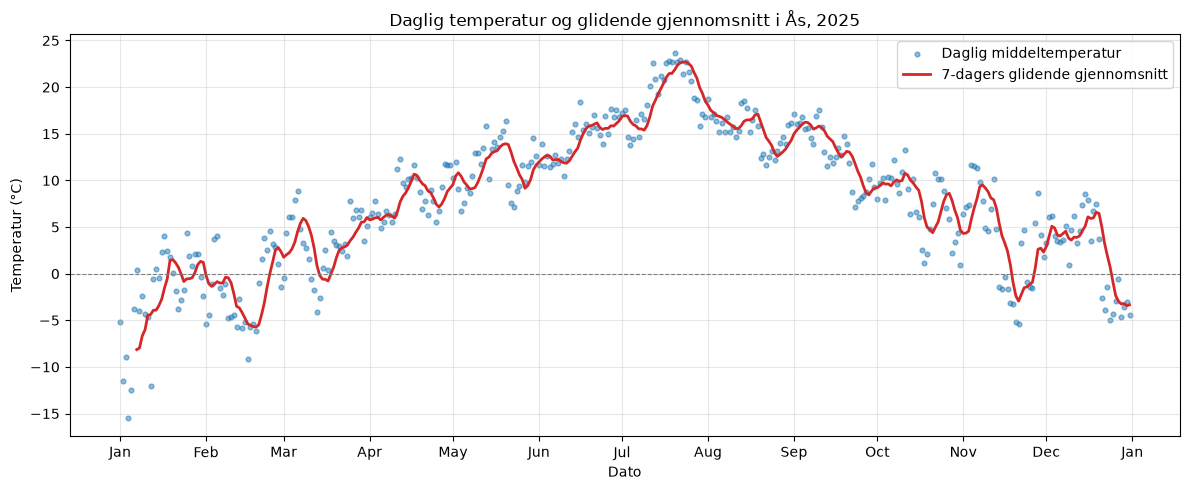

In [6]:
def moving_average(temperature):
    """Beregn et etterslepende gjennomsnitt over sju kalenderdager."""
    daily = temperature.sort_index().asfreq("D")
    return daily.rolling(window=7, min_periods=7).mean()


# Beregn sju dagers glidende gjennomsnitt
average_temps = moving_average(temps)

# Plot daglige temperaturer og glidende gjennomsnitt
fig, ax = plt.subplots(figsize=(12, 5))
ax.scatter(
    temps.index, temps, s=12, color="tab:blue", alpha=0.5,
    label="Daglig middeltemperatur",
)
ax.plot(
    average_temps.index, average_temps, color="tab:red", linewidth=2,
    label="7-dagers glidende gjennomsnitt",
)
ax.axhline(0, color="grey", linewidth=0.8, linestyle="--")
ax.set_title("Daglig temperatur og glidende gjennomsnitt i Ås, 2025")
ax.set_xlabel("Dato")
ax.set_ylabel("Temperatur (°C)")
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()
